In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [4]:
def flatten(data, column):
    print('column:', column)
    a = []
    if (column != 7):
        for row in range(0,len(data)):
            if (len(data[row]['pt']) > 0): 
                a.append(data[row][column][0]) # caveat: only including leading jets
    else:
        for row in range(0,len(data)):
            if (len(data[row]['pt']) > 0): 
                a.append(data[row][column])
    b = np.asarray(a)
    b.astype('float32')
    return b

In [5]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [6]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['weight'])
    n_os = sum(dataframe[dataframe.b==-1]['weight'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [8]:
observables2 = ['pt','m','b','dr','rg','zg','mg','weight','z','epair']

In [9]:
data = root_numpy.root2array('$HOME/output/run12/pythia0413.root', 'ResultTree', branches=observables2)
a = []
for branchName in observables2:
    print(branchName)
    a.append(flatten(data, observables2.index(branchName)))

pt
column: 0
m
column: 1
b
column: 2
dr
column: 3
rg
column: 4
zg
column: 5
mg
column: 6
weight
column: 7
z
column: 8
epair
column: 9


Warning in <TClass::Init>: no dictionary for class TStarJetVectorJet is available
Warning in <TClass::Init>: no dictionary for class TStarJetVector is available


In [10]:
df = pd.DataFrame(np.transpose(a), columns=observables2, dtype='float32')

In [11]:
df.eval('t = 1/(2*epair*z*(1-z)*(1-cos(dr)))', inplace=True)

In [12]:
df = applyCut(df, 'b!=0 and 15<pt<20 and b!=-9')

In [13]:
min(df['t']), max(df['t'])

(1.3460519313812256, 489647.96875)

In [36]:
bins = 10.0**(np.arange(0,4.4,0.4))

In [26]:
bins

array([1.00000000e+00, 2.51188643e+00, 6.30957344e+00, 1.58489319e+01,
       3.98107171e+01, 1.00000000e+02, 2.51188643e+02, 6.30957344e+02,
       1.58489319e+03, 3.98107171e+03, 1.00000000e+04])

Text(0.5, 0, '$\\tau_{form} = [2Ez(1-z)(1-\\mathrm{cos}(\\Delta R))]^{-1}$ [$\\mathrm{GeV}^{-1}$]')

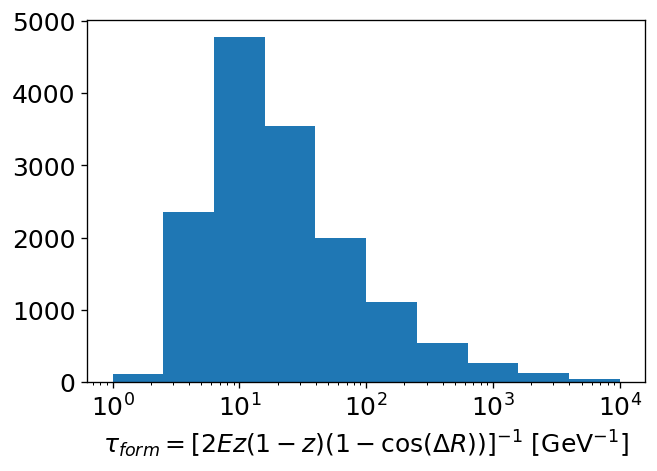

In [27]:
plt.hist(df['t'], bins=bins)
plt.xscale('log')
plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)

In [28]:
bins = 10.0**(np.arange(0.25,4,0.25))

In [37]:
bincenter = (bins[:-1] + bins[1:])/2

In [38]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

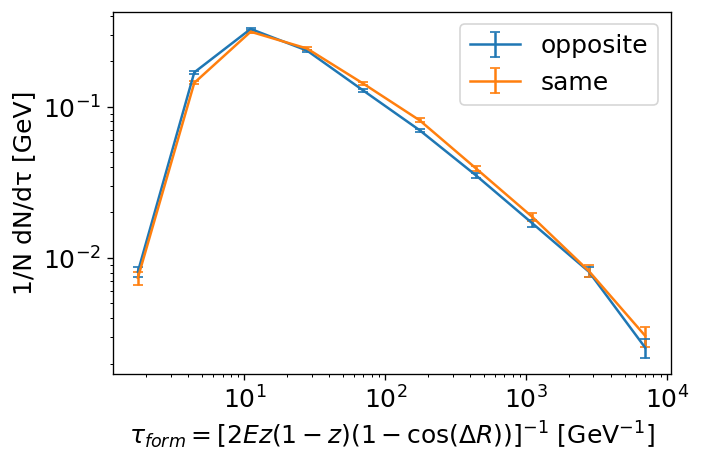

In [39]:
y_os, yerr_os = calc_hist(df[df.b<0]['t'], bins=bins, density=True)[:-1]
y_ss, yerr_ss = calc_hist(df[df.b>0]['t'], bins=bins, density=True)[:-1]
plt.errorbar(bincenter, y_os/sum(y_os), yerr=yerr_os, label='opposite', capsize=3)
plt.errorbar(bincenter, y_ss/sum(y_ss), yerr=yerr_ss, label='same', capsize=3)
plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]')
plt.xscale('log')
#plt.xlim(1, 1e4)
plt.legend()
plt.ylabel('1/N dN/dτ [GeV]')
plt.yscale('log')

In [40]:
dfs = []
for i in range(0, len(bincenter)):
    dfs.append(df[np.logical_and(df.t>bins[i], df.t<bins[i+1])])

In [41]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [42]:
rcs

[-0.33750571171643373,
 -0.16702766075772818,
 -0.18546576671740295,
 -0.18828887157197943,
 -0.18587204204573507,
 -0.05338037935809892,
 -0.1216186453280711,
 -0.10859495844023834,
 -0.12322018335252045,
 0.03268790603408294]

(1, 10000.0)

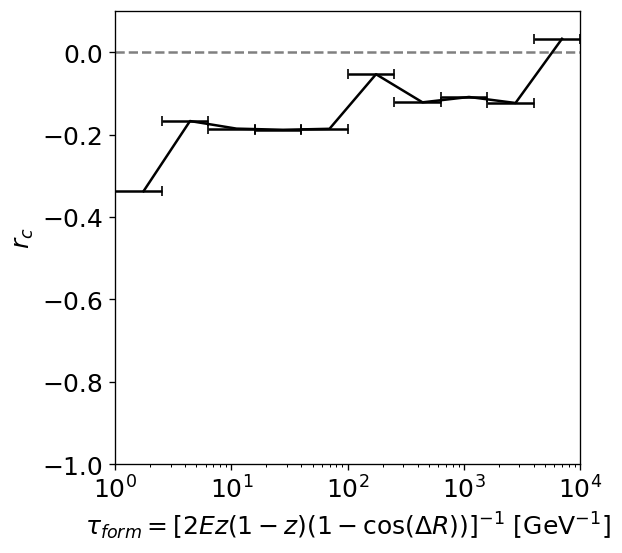

In [43]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs, xerr=np.array(bincenter)-np.array(bins[:-1]), capsize=3, color='k')
plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-1,0.1)
plt.xscale('log')
plt.xlim(1, 1e4)